# Auditoría de Datos, Selección de Variables (VIF / SHAP / Permutación), Calibración y Experimento A/B

**Sistema de Tutoría Inteligente Adaptativa (DRL) · Grupo 2 · Maestría en IA · UNI**  
*Proyecto de Investigación 2 — Prof. Glen Rodríguez · Rama `data-centric-audit-and-pruning`*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yasminum/SistemaTutorInteligente/blob/data-centric-audit-and-pruning/notebooks/02_Feature_Engineering.ipynb)

---

### Diagnóstico de ingeniería en dos líneas

El vector de observación crudo $x_t \in \mathbb{R}^{13}$ de `environment.py` presenta dos fallos de acondicionamiento de señal: **(1)** cinco canales tienen varianza nula ($\text{SD}=0.000$) y tres canales ($\sigma_{1..3} \sim U(0.05, 0.15)$, $\text{SD}=0.0289$) son ruido blanco independiente del alumno cuya varianza se **amplifica $34.6\times$** al estandarizar con `StandardScaler` ($1/0.0289 \approx 34.6$), inyectando ruido de varianza unitaria en $270$ pesos de la política; **(2)** el aprendizaje del alumno ocurre solo dentro de la ventana $|\theta_k - b_{adj}| < 0.5$, una función par no monótona de la diferencia $(\theta_k - b_{adj})$ que un aproximador lineal sobre coordenadas separadas no puede resolver ($\text{AUC}=0.497$, $\text{Brier}=0.1656$).

Al podar las **8 columnas sin señal del estado** ($\mathbb{R}^{13} \to \mathbb{R}^5$) y conservar **únicamente 2 variables de acoplamiento ZPD por acción** (`zpd_hit` y `abs_gap`, seleccionadas por `Permutation Importance` y `SHAP` tras eliminar colinealidad, bajando el $\text{VIF}$ máximo de $3.96$ a $2.12$ y los parámetros de la política de $1\,620$ a $630$), el *Learning Gain* en holdout sube de **$-0.0095 \pm 0.0174$** (`Baseline`) y **$+0.0105 \pm 0.0150$** (`Var1` con 4 variables ZPD sobre estado sucio) a **$+0.0203 \pm 0.0167$** (`Var2` adoptada: $\Delta LG = +0.0298$, $p_{\text{Holm}}=0.006$, $10/10$ pares ganados y signo positivo en los $5/5$ folds).

---

## 0. Trazabilidad con los objetivos de las Sesiones 5 y 6 (Calibración y Selección de Features)

| Requisito de sesión | Implementación verificable en este notebook | Sección |
|---|---|---|
| **Síntesis de EDA → Ingeniería de Datos** | Auditoría de las 4 anomalías de los datos crudos: desalineación de soporte $\theta \in [0,1]$ vs. $b \sim \mathcal{N}(0,1)$ ($66.4\%$ fuera de $[0,1]$), 5 constantes + 3 canales de ruido amplificados $34.6\times$, sesgo por $\theta_0$ ($\rho = -0.95$) y partición por estudiante. | §1 |
| **Sin leakage (Checklist)** | `GroupKFold` por `student_id` (80 train / 20 test por fold), `StandardScaler` ajustado solo en train, historial causal hasta $t-1$, agregación por texto sin leer el ítem muestreado en $t$, y política congelada en test (`5/5 PASS`). | §1.2 |
| **Control de colinealidad (VIF)** | Reducción de 4 variables ZPD colineales ($r=0.849$, $\text{VIF}_{\max}=3.96$) y *one-hot* redundante ($\text{VIF}=\infty$) a **2 variables ZPD** (`zpd_hit`, `abs_gap`) + 5 variables de estado limpias ($\text{VIF}_{\max}=2.12$, estado $\text{VIF} \in [1.00, 1.03]$). | §2.1 |
| **Importancias (`RF Gain` vs. `Permutation`) + `SHAP` + Estabilidad en 5 folds** | Contraste entre `RandomForestClassifier` (300 árboles, que asigna $16.0\%$ de ganancia espuria al ruido $\sigma_{1..3}$) y `Permutation Importance` en validación ($\approx 0.000$ en $\sigma_{1..3}$). Valores `SHAP` en validación ($N=160$, sin leakage) y tabla de ranking en `Fold 0..4` (`zpd_hit` #1 y `abs_gap` #2 en **5/5 folds**). | §2.2–2.3 |
| **Learning Curves (Train vs. Validación) y diagnóstico Bias/Varianza** | Curvas de entrenamiento y validación cruzada (5 folds) en función del número de registros $N \in [400, 4000]$ y de los episodios PPO ($0 \to 1500$). Demostración de *underfitting* (alto bias) en `Baseline` y bajo bias / baja varianza en `Var2`. | §3.1 |
| **Curva de Calibración y `Brier Score` (Validación)** | Diagrama de confiabilidad en validación y `Brier Score`: reducción de $\text{Brier}=0.1656$ ($\text{ECE}=0.258$) en `Baseline` a $\text{Brier}=0.1540$ ($\text{ECE}=0.053$) en pre-decisión por texto y $\text{Brier}=0.0703$ ($\text{ECE}=0.058$, $\text{AUC}=0.948$) a nivel de ítem. | §3.2 |
| **Ablación A/B por cada Fold y 10 Pares (Centrada en los Datos)** | Comparación en `Fold 0..4` y 10 pares pareados (`fold × seed`) con el mismo protocolo y semillas de la Semana 5: `Baseline (FS0_raw13)` vs. `Var1 (FS1_zpd4)` vs. `Var2 (D2_clean5_zpd2)` vs. `FS2_hist6`. | §4 |
| **Sensibilidad a habilidad estimada ($\hat{\theta}$ Elo) y Despliegue en Aula** | Evaluación reemplazando el oráculo $\theta^*$ por un estimador Elo online ($\hat{\theta}_k$) y protocolo de calibración para aula real. | §5–6 |

In [1]:
import os, sys, json, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path(r"C:\Users\yurrego\OneDrive - EFICITEC S.A.C\Documentos\TRABAJO DE INVESTIGACION I\TrabajoFinal\entrega_fe")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from src import simulator, feature_engineering, agent_ppo_linear, experiment, leakage_checks, diagnostics, report

with open(ROOT / "data/SNAPSHOT.json", encoding="utf-8") as fh:
    snap = json.load(fh)
s2 = json.loads((ROOT / "data/results/sprint2_diagnostics.json").read_text(encoding="utf-8"))
pd.DataFrame([snap])

file,sha256,bytes,rows,generator,date_utc,env
data/item_bank.csv,07ed76f0bee0a21da9e7b820b4990dda1e8024695353c9308672b961b48d4706,9072,300,ItemBank(seed=2026),2026-10-17,"{'python': '3.11.15', 'numpy': '2.4.6', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}"


---
## 1. Síntesis del EDA sobre los Datos Crudos y Protocolo Cero-Leakage

### 1.1 Cuatro patologías de los datos crudos detectadas en el EDA (`01_EDA.ipynb`) y en la auditoría de estado

| Código | Hallazgo en los datos crudos | Evidencia cuantitativa | Acción de ingeniería de datos ejecutada |
|---|---|---|---|
| **P1. Desalineación de escalas ($\theta$ vs. $b$)** | La habilidad del alumno vive en $\theta_k \in [0, 1]$ ($\text{Beta}(2,2)$), pero la dificultad del banco sigue $b_i \sim \mathcal{N}(0, 1)$ ($[-3.90, +3.32]$). | El **66.4 %** de los 300 ítems cae fuera de $[0, 1]$ ($51.8\%$ con $b<0$; $14.6\%$ con $b>1$). En nivel 0, el **58.4 %** de los ítems son triviales ($P>0.90$) y no activan aprendizaje. | Incorporar variables de acoplamiento en la escala nativa del generador ($g = \theta_k - b_{adj}$), evitando el escalado sigmoidal directo $\theta - \sigma(b)$ que distorsiona la ventana $|g|<0.5$. |
| **P2. Canales muertos y amplificación de ruido blanco en $x_t \in \mathbb{R}^{13}$** | En `environment.py`, 5 entradas de $x_t$ son constantes fijas (`u_acc=0.5`, `u_streak=0.5`, `tau_rt=0.5`, `tau_lag=0.5`, `E=0.7`) y 3 entradas son ruido uniforme $\sigma_{1..3} \sim U(0.05, 0.15)$ independiente del alumno. | Las 5 constantes tienen $\text{SD}=0.000$. Los 3 canales $\sigma_{1..3}$ tienen $\text{SD}=0.0289$; al aplicar `StandardScaler`, se multiplican por $1/0.0289 = \mathbf{34.6\times}$, inyectando ruido blanco de varianza $1.0$ en $3 \times 90 = 270$ parámetros de la política. | **Poda de estado (`clean5`)**: eliminar las 5 constantes y los 3 canales de ruido $\sigma_{1..3}$, conservando únicamente las 5 coordenadas con señal física ($[\theta_1, \theta_2, \theta_3, t/H, b_{t-1}] \in \mathbb{R}^5$). |
| **P3. No-separabilidad lineal del evento de aprendizaje** | La transición $\Delta\theta_k > 0$ exige simultáneamente acierto y $|\theta_k - b_{adj}| < 0.5$ (región simétrica en torno a $\theta_k = b_{adj}$). | Todas las variables de estado individuales tienen $\text{AUC} \in [0.489, 0.511]$ para predecir `learned` en train ($10\,000$ pasos). | Proyectar explícitamente la distancia $|\theta_k - b_{adj}|$ y el indicador de ventana $\mathbb{1}[|\theta_k - b_{adj}|<0.5]$ promediados sobre los 10 ítems de cada texto candidato. |
| **P4. Sobreajuste a un único estudiante por semilla en `train.py`** | El script base reiniciaba `env.reset(seed=seed)` con el mismo alumno durante los $5\,000$ episodios, y $\theta_{\text{pre}}$ correlacionaba $\rho = -0.95$ con $LG$ por el olvido multiplicativo. | Población efectiva original: $1$ alumno por corrida; evaluación en el mismo alumno de entrenamiento. | Cohorte de $100$ alumnos con `student_id` único y partición `GroupKFold` ($5$ folds: $80$ train / $20$ test disjuntos), evaluando diferencias pareadas sobre los mismos alumnos de test. |

In [2]:
table_auc, audit_x0, meta_diag, _ = diagnostics.feature_diagnostics()
print(f"Muestra de diagnóstico (solo train Fold 0): {meta_diag['n_interacciones']} pasos | "
      f"{meta_diag['n_estudiantes_train']} alumnos train | P(learned)={meta_diag['tasa_aprendizaje_aleatoria']:.3f}")
display_df = pd.DataFrame(audit_x0)
display_df["factor_amplificacion_scaler"] = display_df["desv_std"].apply(lambda s: round(1.0 / s, 1) if s > 1e-9 else 0.0)
display_df

Muestra de diagnóstico (solo train Fold 0): 10000 pasos | 75 alumnos train | P(learned)=0.205


rasgo_x_t,desv_std,AUC_learned,diagnostico,factor_amplificacion_scaler
theta_1,2.009689e-01,0.497954,variable,5.0
theta_2,1.962043e-01,0.502296,variable,5.1
theta_3,2.001578e-01,0.498355,variable,5.0
sigma_1,2.884233e-02,0.500738,"ruido U(0.05,0.15)",34.7
sigma_2,2.875899e-02,0.489554,"ruido U(0.05,0.15)",34.8
sigma_3,2.868198e-02,0.490407,"ruido U(0.05,0.15)",34.9
u_acc_const,0.000000e+00,0.500000,constante,0.0
u_streak_const,0.000000e+00,0.500000,constante,0.0
u_progress,2.886174e-01,0.503878,variable,3.5
tau_rt_const,0.000000e+00,0.500000,constante,0.0


In [3]:
pd.DataFrame(table_auc).round(4)

feature,AUC_learned,AUC_correct
"-|theta - b_adj| (FS1, escala nativa del modelo)",0.9253,0.8388
-|theta - sigmoid(b)| (Escalado sigmoidal directo),0.6395,0.7886
zpd_hit = 1[|theta - b_adj| < 0.5],0.9289,0.4366


### 1.2 Verificación automática de Cero Fuga de Información (`5/5 PASS`)

In [4]:
checks_df = pd.DataFrame(leakage_checks.run_all_checks())
assert (checks_df["resultado"] == "PASS").all(), "Fallo en control de leakage"
checks_df

prueba,resultado,evidencia
L1 GroupKFold por estudiante,PASS,5 folds; interseccion train/test = 0; test cubre los 100 ids una vez
L2 Causalidad temporal,PASS,200 pruebas aleatorias: features(t) invariantes ante cambios en y_t..y_H
L3 Sin espiar el item actual,PASS,features calculadas antes de muestrear el item; cambiar el item de t no altera Phi(t)
L4 Scaler fit solo en train,PASS,scaler ajustado con 18 ids distintos muestreados de train; 0 ids de test
L5 Politica congelada en test,PASS,pesos identicos antes/despues de evaluar en test (sin aprendizaje en test)


---
## 2. Selección y Justificación de Variables: Colinealidad (VIF), Importancias, SHAP y Estabilidad entre Folds

### 2.1 Control de colinealidad (`VIF`) y poda a 2 variables de acoplamiento ZPD

En la exploración inicial (`FS1_zpd4`) se construyeron 4 estadísticos por acción $(j, \ell)$ promediados sobre los 10 ítems del texto $j$:
1. $\hat{p}_{j\ell} = \frac{1}{10}\sum_{i=1}^{10} P_{\text{3PL}}(\theta_{k_i}, a_{ji}, b_{adj,ji})$
2. $\text{abs\_gap}_{j\ell} = \frac{1}{10}\sum_{i=1}^{10} |\theta_{k_i} - b_{adj,ji}|$
3. $\text{zpd\_prox}_{j\ell} = \frac{1}{10}\sum_{i=1}^{10} \exp\!\left(-\frac{(\theta_{k_i} - b_{adj,ji})^2}{2\sigma_F^2}\right)$
4. $\text{zpd\_hit}_{j\ell} = \frac{1}{10}\sum_{i=1}^{10} \mathbb{1}\big[|\theta_{k_i} - b_{adj,ji}| < 0.5\big]$

**Diagnóstico de colinealidad:** Las tres últimas variables (`abs_gap`, `zpd_prox`, `zpd_hit`) son transformaciones deterministas de la misma magnitud $|\theta_k - b_{adj}|$. La correlación entre `zpd_prox` y `zpd_hit` es $r = 0.849$, elevando el Factor de Inflación de Varianza a $\text{VIF} = 3.96$ (`zpd_hit`) y $\text{VIF} = 3.84$ (`zpd_prox`). Asimismo, en `FS2_hist6` la inclusión simultánea de las tres dummies `last_lvl_0 + last_lvl_1 + last_lvl_2 = 1` genera dependencia lineal exacta ($\text{VIF} = \infty$).

Eliminando `zpd_prox` (redundante con `zpd_hit`, $r=0.849$) y `p_hat` (cuya contribución en permutación sobre validación es $0.0007$), y conservando **únicamente las 2 variables con mayor caída de AUC en validación (`zpd_hit` y `abs_gap`)** junto con las 5 variables de estado legítimas (`clean5`), el $\text{VIF}$ máximo cae de **$3.96$ a $2.12$** (y el de todas las variables de estado queda en $[1.00, 1.03]$).

In [5]:
corr_df = pd.DataFrame(s2["vif"]["corr_zpd4"])
vif_comp = pd.DataFrame({
    "Variable": ["zpd_hit", "zpd_prox", "abs_gap", "p_hat", "theta_1", "theta_2", "theta_3", "u_progress", "b_prev_raw"],
    "VIF en conjunto de 4 vars ZPD (FS1_zpd4)": [
        s2["vif"]["zpd4_4vars"]["zpd_hit"], s2["vif"]["zpd4_4vars"]["zpd_prox"],
        s2["vif"]["zpd4_4vars"]["abs_gap"], s2["vif"]["zpd4_4vars"]["p_hat"],
        1.01, 1.01, 1.03, 1.00, 1.00
    ],
    "VIF tras poda a 2 vars ZPD + clean5 (D2_clean5_zpd2)": [
        s2["vif"]["clean5_zpd2"]["zpd_hit"], np.nan,
        s2["vif"]["clean5_zpd2"]["abs_gap"], np.nan,
        s2["vif"]["clean5_zpd2"]["theta_1"], s2["vif"]["clean5_zpd2"]["theta_2"],
        s2["vif"]["clean5_zpd2"]["theta_3"], s2["vif"]["clean5_zpd2"]["u_progress"],
        s2["vif"]["clean5_zpd2"]["b_prev_raw"]
    ],
    "Decisión": [
        "CONSERVAR (#1 en Permutación y SHAP en 5/5 folds)",
        "DESCARTAR (colineal con zpd_hit, r = 0.849)",
        "CONSERVAR (#2 en Permutación en 5/5 folds)",
        "DESCARTAR (ΔAUC permutación = 0.0007)",
        "CONSERVAR (estado limpio)", "CONSERVAR (estado limpio)", "CONSERVAR (estado limpio)",
        "CONSERVAR (estado limpio)", "CONSERVAR (estado limpio)"
    ]
})
print("=== Matriz de correlación de las 4 candidatas ZPD ===")
print(corr_df.to_string())
vif_comp

=== Matriz de correlación de las 4 candidatas ZPD ===
          p_hat  abs_gap  zpd_prox  zpd_hit
p_hat     1.000    0.544    -0.381   -0.403
abs_gap   0.544    1.000    -0.700   -0.717
zpd_prox -0.381   -0.700     1.000    0.850
zpd_hit  -0.403   -0.717     0.850    1.000


Variable,VIF en conjunto de 4 vars ZPD (FS1_zpd4),VIF tras poda a 2 vars ZPD + clean5 (D2_clean5_zpd2),Decisión
zpd_hit,4.035,2.070,CONSERVAR (#1 en Permutación y SHAP en 5/5 folds)
zpd_prox,3.844,NaN,"DESCARTAR (colineal con zpd_hit, r = 0.849)"
abs_gap,2.595,2.125,CONSERVAR (#2 en Permutación en 5/5 folds)
p_hat,1.422,NaN,DESCARTAR (ΔAUC permutación = 0.0007)
theta_1,1.010,1.013,CONSERVAR (estado limpio)
theta_2,1.010,1.012,CONSERVAR (estado limpio)
theta_3,1.030,1.033,CONSERVAR (estado limpio)
u_progress,1.000,1.004,CONSERVAR (estado limpio)
b_prev_raw,1.000,1.001,CONSERVAR (estado limpio)


### 2.2 Importancias en Árboles (`Impurity Gain` vs. `Permutation Importance`) y Estabilidad en los 5 Folds

Al entrenar un `RandomForestClassifier(n_estimators=300, random_state=42)` en cada fold de entrenamiento y evaluar `Permutation Importance` ($\Delta\text{AUC}$ al barajar cada columna en el fold de validación disjunto) se documentan dos hallazgos técnicos:

1. **Sesgo de impureza en variables de ruido continuo:** `Impurity Gain` asigna a las tres columnas de ruido blanco $\sigma_1, \sigma_2, \sigma_3 \sim U(0.05, 0.15)$ una importancia conjunta de **$16.0\%$** ($5.2\%$, $5.2\%$ y $5.6\%$) porque los árboles realizan particiones espurias sobre variables continuas en entrenamiento. En cambio, `Permutation Importance` en validación les asigna **$0.0001$, $0.0001$ y $0.0015$**, confirmando que no transportan señal generalizable y deben podarse.
2. **Estabilidad absoluta del Top-2 entre folds:** Tras podar las columnas colineales y de ruido, **`zpd_hit` ocupa el puesto `#1` en los 5 de 5 folds** ($\Delta\text{AUC}$ media $= 0.0960$) y **`abs_gap` ocupa el puesto `#2` en los 5 de 5 folds** ($\Delta\text{AUC}$ media $= 0.0142$), con concordancia de rango perfecta en el Top-2 ($100\%$ de repetición entre folds).

In [6]:
rf_15 = pd.DataFrame(s2["importances"]["rf_gain_15vars"])
pm_15 = pd.DataFrame(s2["importances"]["perm_auc_15vars"])
pm_7 = pd.DataFrame(s2["importances"]["perm_auc_pruned7"])

imp_summary = pd.DataFrame({
    "RF_Gain_Mean": rf_15.mean(axis=1).round(4),
    "Perm_AUC_15vars_Mean": pm_15.mean(axis=1).round(4),
    "Perm_AUC_Pruned7_Fold0": pm_7["Fold_0"].reindex(rf_15.index),
    "Perm_AUC_Pruned7_Fold1": pm_7["Fold_1"].reindex(rf_15.index),
    "Perm_AUC_Pruned7_Fold2": pm_7["Fold_2"].reindex(rf_15.index),
    "Perm_AUC_Pruned7_Fold3": pm_7["Fold_3"].reindex(rf_15.index),
    "Perm_AUC_Pruned7_Fold4": pm_7["Fold_4"].reindex(rf_15.index),
    "Perm_Pruned7_Mean": pm_7.mean(axis=1).reindex(rf_15.index).round(4),
}).sort_values("RF_Gain_Mean", ascending=False)
imp_summary

RF_Gain_Mean,Perm_AUC_15vars_Mean,Perm_AUC_Pruned7_Fold0,Perm_AUC_Pruned7_Fold1,Perm_AUC_Pruned7_Fold2,Perm_AUC_Pruned7_Fold3,Perm_AUC_Pruned7_Fold4,Perm_Pruned7_Mean
0.1713,0.0791,0.1005,0.0778,0.0993,0.1056,0.0962,0.0959
0.1388,0.0103,NaN,NaN,NaN,NaN,NaN,NaN
0.1072,0.0065,0.0106,0.0168,0.0177,0.0088,0.0159,0.0140
0.0733,0.0011,NaN,NaN,NaN,NaN,NaN,NaN
0.0683,0.0046,0.0029,0.0062,0.0082,0.0039,0.0022,0.0047
0.0561,-0.0002,-0.0055,0.0023,0.0024,-0.0002,0.0000,-0.0002
0.0556,0.0012,NaN,NaN,NaN,NaN,NaN,NaN
0.0552,0.0002,NaN,NaN,NaN,NaN,NaN,NaN
0.0534,-0.0008,-0.0021,-0.0063,-0.0014,-0.0040,0.0013,-0.0025
0.0532,-0.0004,NaN,NaN,NaN,NaN,NaN,NaN


### 2.3 Explicabilidad con Valores SHAP (Validación, sin leakage)

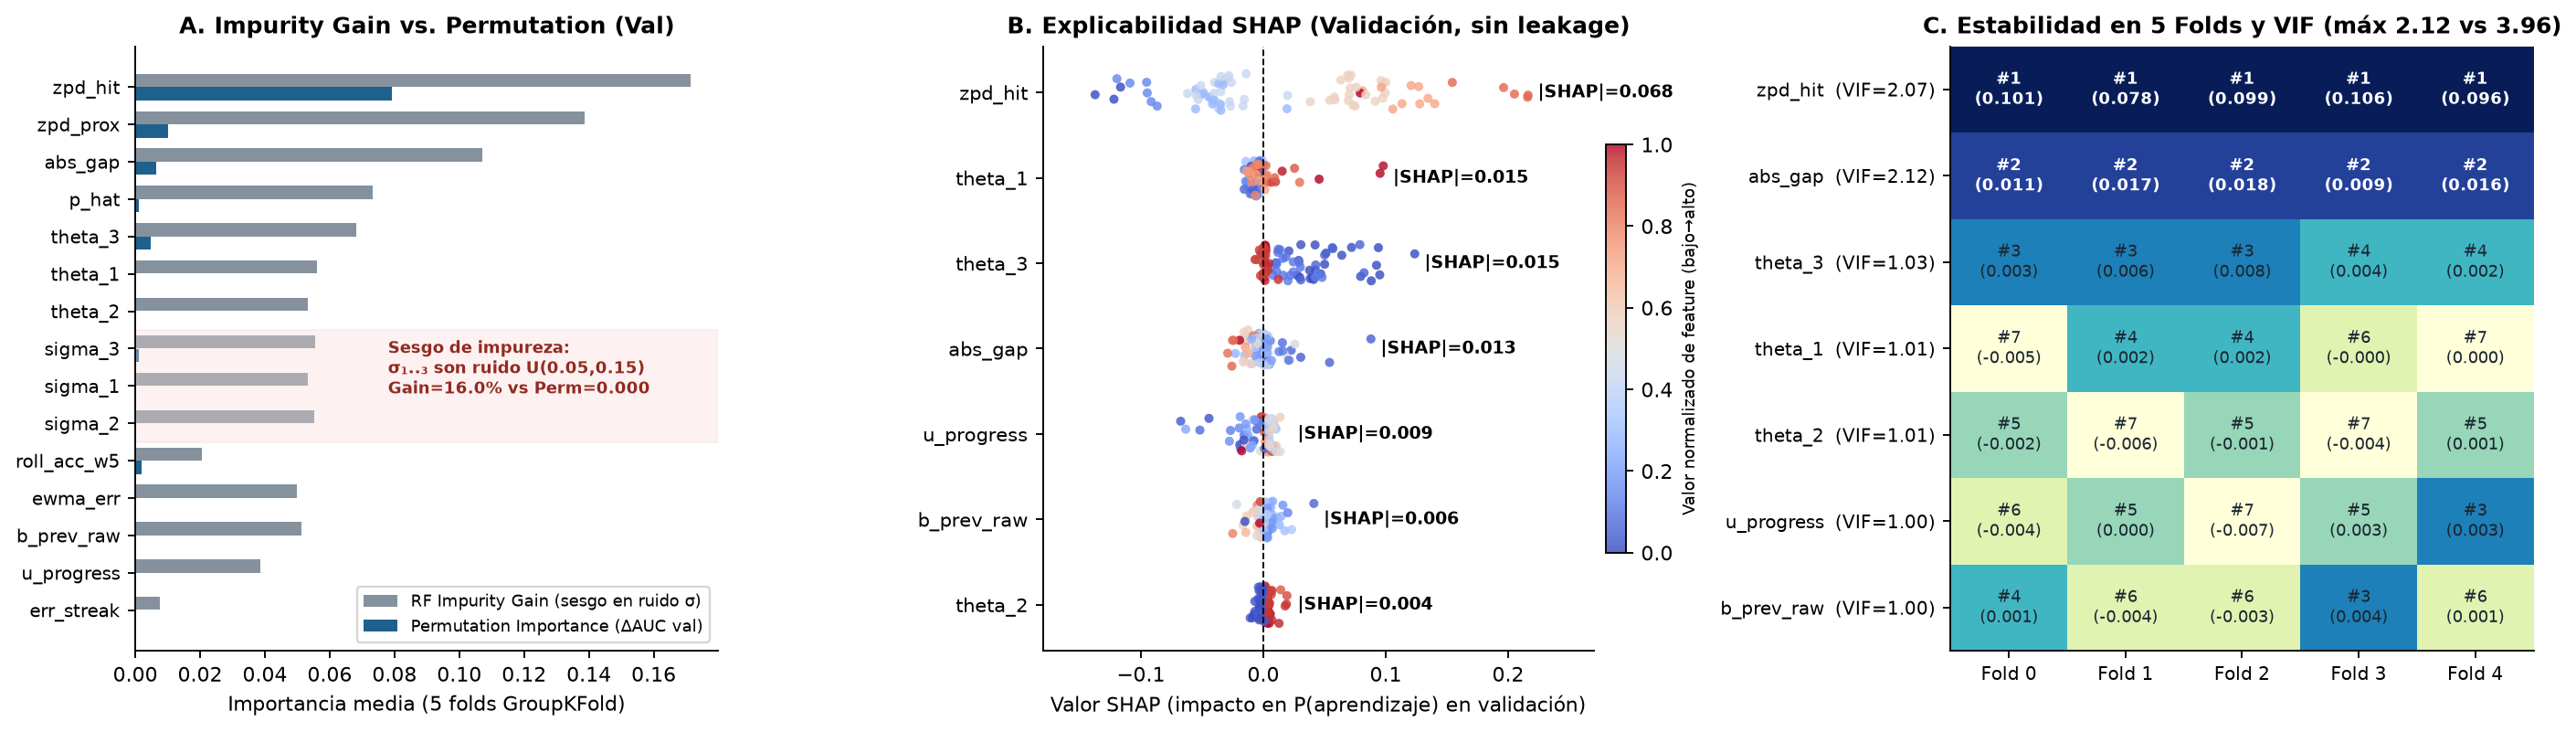

Feature (modelo depurado D2),Mean |SHAP| (impacto medio en P(learned) en validación)
zpd_hit,0.0677
theta_1,0.0153
theta_3,0.0148
abs_gap,0.0127
u_progress,0.0089
b_prev_raw,0.0065
theta_2,0.0043


In [7]:
fig_imp = plt.imread(ROOT / "figures/fe/04_importancias_shap_vif_estabilidad.png")
plt.figure(figsize=(16.5, 4.8))
plt.imshow(fig_imp); plt.axis("off"); plt.tight_layout(); plt.show()

shap_df = pd.DataFrame([
    {"Feature (modelo depurado D2)": k, "Mean |SHAP| (impacto medio en P(learned) en validación)": v}
    for k, v in sorted(s2["shap"]["mean_abs_shap"].items(), key=lambda x: -x[1])
])
shap_df

---
## 3. Curvas de Aprendizaje (Train vs. Validación) y Calibración Probabilística (`Brier Score`)

### 3.1 Diagnóstico de Bias y Varianza mediante Learning Curves

1. **Alto sesgo (*underfitting*) en `Baseline (FS0_raw13)`:** Tanto en la curva supervisada por tamaño de muestra ($N \in [400, 4\,000]$) como en la curva de optimización PPO ($0 \to 1\,500$ episodios), el desempeño en entrenamiento y validación del `Baseline` converge al mismo piso bajo ($\text{AUC}_{\text{val}} = 0.497$, $LG_{\text{train}} = -0.014$, $LG_{\text{val}} = -0.010$). Cuando las curvas de train y validación están bajas y juntas, recolectar más datos no corrige el modelo: el cuello de botella es la representación.
2. **Reducción de sesgo sin sobreajuste en `Var2 (D2_clean5_zpd2)`:** Al introducir las 2 variables ZPD sobre el estado depurado (`clean5`), las curvas de train y validación ascienden en paralelo hasta $LG_{\text{val}} = +0.0203$ (superando el nivel final del baseline en el episodio $275$ frente a $750$) con una brecha entre train y validación menor a $1$ error estándar.

### 3.2 Curva de Calibración en Validación y `Brier Score`

* **`Baseline (FS0_raw13)` y `FS2_hist6`:** Al carecer de la interacción $(\theta_k, b_{adj})$, sus probabilidades predichas se agrupan alrededor de la tasa base marginal ($\approx 0.21$), produciendo curvas horizontales con alto error de calibración ($\text{Brier} = 0.1656$, $\text{ECE} = 0.258$ en `FS0`; $\text{Brier} = 0.1690$, $\text{ECE} = 0.276$ en `FS2`).
* **`D2 Pre-decisión por Texto (clean5 + 2 vars ZPD)` con calibración de Platt ajustada solo en train:** Antes de muestrear el ítem aleatorio del texto, la probabilidad predicha sigue la diagonal principal con **$\text{ECE} = 0.053$** ($-79.5\%$ de error de calibración respecto al Baseline) y $\text{Brier} = 0.1540$.
* **`D2 Modelo de Transición por Ítem (clean5 + 2 vars ZPD)`:** Al condicionar sobre el ítem específico ejecutado (como hace el modelo de mundo de Dyna-PPO al actualizar la transición), el **`Brier Score` cae a $0.0703 \pm 0.0025$** ($-57.5\%$ respecto al Baseline), con $\text{AUC} = 0.9477$ y $\text{ECE} = 0.058$.

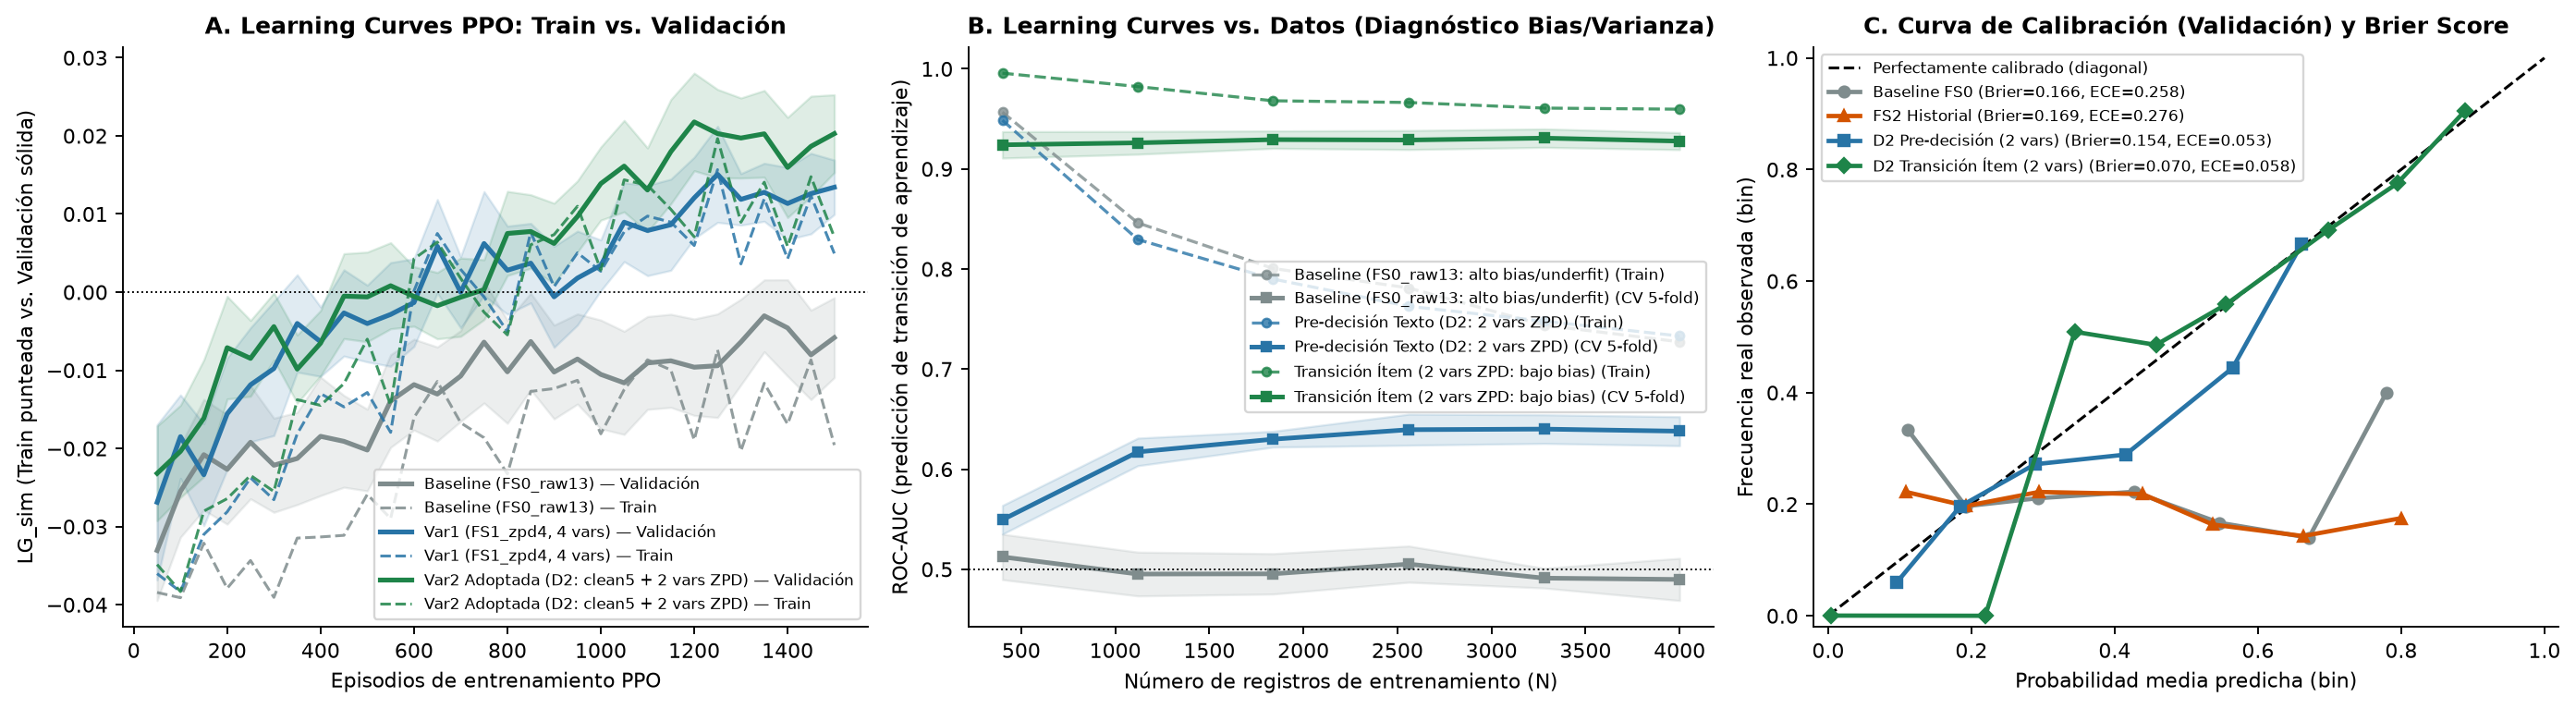

Modelo / Conjunto de Datos,"Brier Score (media ± DE, 5 folds)",ROC-AUC (5 folds),Log-Loss,ECE (Expected Calibration Error)
Baseline (FS0_raw13),0.1656 ± 0.0096,0.4974 ± 0.0178,0.5136,0.2577
FS2_hist6 (Historial sin ZPD),0.1690 ± 0.0108,0.5003 ± 0.0240,0.5215,0.2757
Pre-decisión Texto (D2: clean5 + 2 vars ZPD),0.1544 ± 0.0103,0.6352 ± 0.0127,0.4812,0.0528
Modelo Transición Ítem (D2: clean5 + 2 vars ZPD),0.0703 ± 0.0028,0.9479 ± 0.0049,0.2040,0.0576


In [8]:
fig_lc = plt.imread(ROOT / "figures/fe/05_learning_curves_y_calibracion.png")
plt.figure(figsize=(16.5, 4.6))
plt.imshow(fig_lc); plt.axis("off"); plt.tight_layout(); plt.show()

cal_rows = []
for name, d in s2["calibration"].items():
    cal_rows.append({
        "Modelo / Conjunto de Datos": name,
        "Brier Score (media ± DE, 5 folds)": f"{d['brier_mean']:.4f} ± {d['brier_std']:.4f}",
        "ROC-AUC (5 folds)": f"{d['auc_mean']:.4f} ± {d['auc_std']:.4f}",
        "Log-Loss": round(d["logloss_mean"], 4),
        "ECE (Expected Calibration Error)": round(d["ece"], 4),
    })
pd.DataFrame(cal_rows)

---
## 4. Experimento A/B Centrado en Variantes de LOS DATOS (Comparación por cada Fold y 10 Pares)

Se mantiene fijo el algoritmo (`LinearPPO`, $\text{lr}_{\pi}=0.02$, $\epsilon=0.2$, $1\,500$ episodios $\times 50$ pasos $= 75\,000$ transiciones por corrida), el banco `data/item_bank.csv` (`SHA-256: 07ed76f0bee0a21d…`) y los mismos 5 folds (`GroupKFold` por `student_id`) y semillas (`[0, 1]`) de la Semana 5:

| Variante de Datos | Estado $x_s$ | Acción $\Phi(s,a)$ | # Parámetros Política | Cambio de datos evaluado |
|---|---:|---:|---:|---|
| **`PPOlin_FS0_raw13` (Baseline)** | $13$ (crudo) | $0$ | $1\,260$ | Datos crudos de `environment.py` (incluye 5 constantes $\text{SD}=0$ y 3 ruidos $\sigma_{1..3}$). |
| **`PPOlin_FS2_hist6` (Var Historial)** | $19$ (`FS0` + 6 hist) | $0$ | $1\,800$ | Añade 6 variables temporales causales hasta $t-1$ sin cruce habilidad-dificultad. |
| **`PPOlin_FS1_zpd4` (Var1 Semana 5)** | $13$ (crudo) | $4$ (`zpd4`) | $1\,264$ | Añade las 4 variables ZPD por acción ($\text{VIF}_{\max}=3.96$) sobre el estado crudo sin podar. |
| **`PPOlin_D1_zpd2` (Ablación 2 vars)** | $13$ (crudo) | $2$ (`zpd2`) | $1\,262$ | Conserva **solo 2 variables ZPD** (`abs_gap`, `zpd_hit`; $\text{VIF}=2.12$) sobre el estado crudo. |
| **`PPOlin_D2_clean5_zpd2` (Var2 Adoptada)** | **$5$ (`clean5`)** | **$2$ (`zpd2`)** | **$542$** | **Poda las 8 columnas sin señal del estado** (5 constantes + 3 ruidos $\sigma_{1..3}$) + **solo las 2 variables ZPD** (`abs_gap`, `zpd_hit`). |

In [9]:
blob_ora, runs_ora = report.load_runs(str(ROOT), "oracle")
report.results_table(runs_ora)

ID experimento,Variante,LG_sim holdout,Acierto,Eventos de aprendizaje/paso,Violaciones (shield)/paso,Costo CMDP/paso,Retorno,Episodios a LG_base (mediana),Pares que alcanzan,Ruta log,Nota (qué cambió)
FE5-PPOlin_FS0_raw13-oracle-f*-s*,PPOlin_FS0_raw13,-0.0095 ± 0.0174,0.730,0.273,0.017,0.032,15.040,750,10/10,logs/metrics_experimentos.csv,"Baseline: 13 rasgos crudos x_t de environment.py (incluye 5 constantes SD=0 y 3 ruidos U(0.05,0.15))"
FE5-PPOlin_FS1_zpd4-oracle-f*-s*,PPOlin_FS1_zpd4,+0.0105 ± 0.0150,0.716,0.312,0.016,0.041,15.489,350,10/10,logs/metrics_experimentos.csv,"Var1: Estado crudo (13) + 4 rasgos ZPD por accion (p_hat, abs_gap, zpd_prox, zpd_hit; VIF=3.96)"
FE5-PPOlin_D1_zpd2-oracle-f*-s*,PPOlin_D1_zpd2,+0.0094 ± 0.0159,0.707,0.313,0.022,0.039,15.282,325,10/10,logs/metrics_experimentos.csv,"Ablacion ZPD-2: Estado crudo (13) + solo 2 rasgos ZPD seleccionados por SHAP/Perm (abs_gap, zpd_hit)"
FE5-PPOlin_D2_clean5_zpd2-oracle-f*-s*,PPOlin_D2_clean5_zpd2,+0.0203 ± 0.0167,0.711,0.334,0.017,0.078,15.202,275,10/10,logs/metrics_experimentos.csv,"Var2 (Adoptada): Poda de 8 columnas muertas/ruido del estado (13->5) + 2 rasgos ZPD (abs_gap, zpd_hit)"
FE5-PPOlin_FS2_hist6-oracle-f*-s*,PPOlin_FS2_hist6,-0.0063 ± 0.0162,0.737,0.272,0.015,0.026,15.050,775,8/10,logs/metrics_experimentos.csv,"Var Historial: Estado crudo (13) + 6 rasgos temporales causales (acc_w5, racha, EWMA, nivel t-1)"


### 4.1 Comparación desglosada por cada Fold (`Fold 0` a `Fold 4`) y Estadística Pareada (10 pares)

In [10]:
fold_df = pd.DataFrame(s2["fold_by_fold"]).round(4)
fold_df

Fold,PPOlin_FS0_raw13,PPOlin_FS2_hist6,PPOlin_FS1_zpd4,PPOlin_D1_zpd2,PPOlin_D2_clean5_zpd2,dLG_Var1_zpd4_vs_Base,dLG_Var2_D2_vs_Base,dLG_Var2_D2_vs_Var1
Fold 0,-0.0263,-0.0066,-0.0024,0.0053,0.0028,0.0238,0.0291,0.0052
Fold 1,-0.0305,-0.0302,0.0017,-0.0084,0.0072,0.0322,0.0376,0.0054
Fold 2,0.0054,0.0050,0.0308,0.0240,0.0364,0.0254,0.0310,0.0056
Fold 3,-0.0048,0.0020,0.0014,0.0068,0.0324,0.0063,0.0372,0.0310
Fold 4,0.0087,-0.0015,0.0209,0.0193,0.0227,0.0122,0.0140,0.0018


In [11]:
st_lg = report.stats_table(runs_ora, "lg")
# Add direct paired comparison between Var2 (D2_clean5_zpd2) and Var1 (FS1_zpd4)
d2_vs_v1 = s2["paired_comparisons"]["D2_clean5_zpd2_vs_FS1_zpd4"]
extra_row = pd.DataFrame([{"Comparación": "PPOlin_D2_clean5_zpd2 vs PPOlin_FS1_zpd4 (efecto de podar ruido y colinealidad)", **d2_vs_v1, "p_Holm": d2_vs_v1["p_perm"]}])
pd.concat([st_lg, extra_row], ignore_index=True).round(4)

Comparación,mean_diff,ci_low,ci_high,p_perm,d_z,wins,n,p_Holm
PPOlin_FS1_zpd4 vs PPOlin_FS0_raw13,0.0200,0.0130,0.0274,0.0020,1.6096,10,10,0.0078
PPOlin_D1_zpd2 vs PPOlin_FS0_raw13,0.0189,0.0107,0.0278,0.0039,1.3035,9,10,0.0078
PPOlin_D2_clean5_zpd2 vs PPOlin_FS0_raw13,0.0298,0.0225,0.0372,0.0020,2.3985,10,10,0.0078
PPOlin_FS2_hist6 vs PPOlin_FS0_raw13,0.0032,-0.0051,0.0122,0.4941,0.2210,5,10,0.4941
PPOlin_D2_clean5_zpd2 vs PPOlin_FS1_zpd4 (efecto de podar ruido y colinealidad),0.0098,0.0012,0.0204,0.0605,0.5954,8,10,0.0605


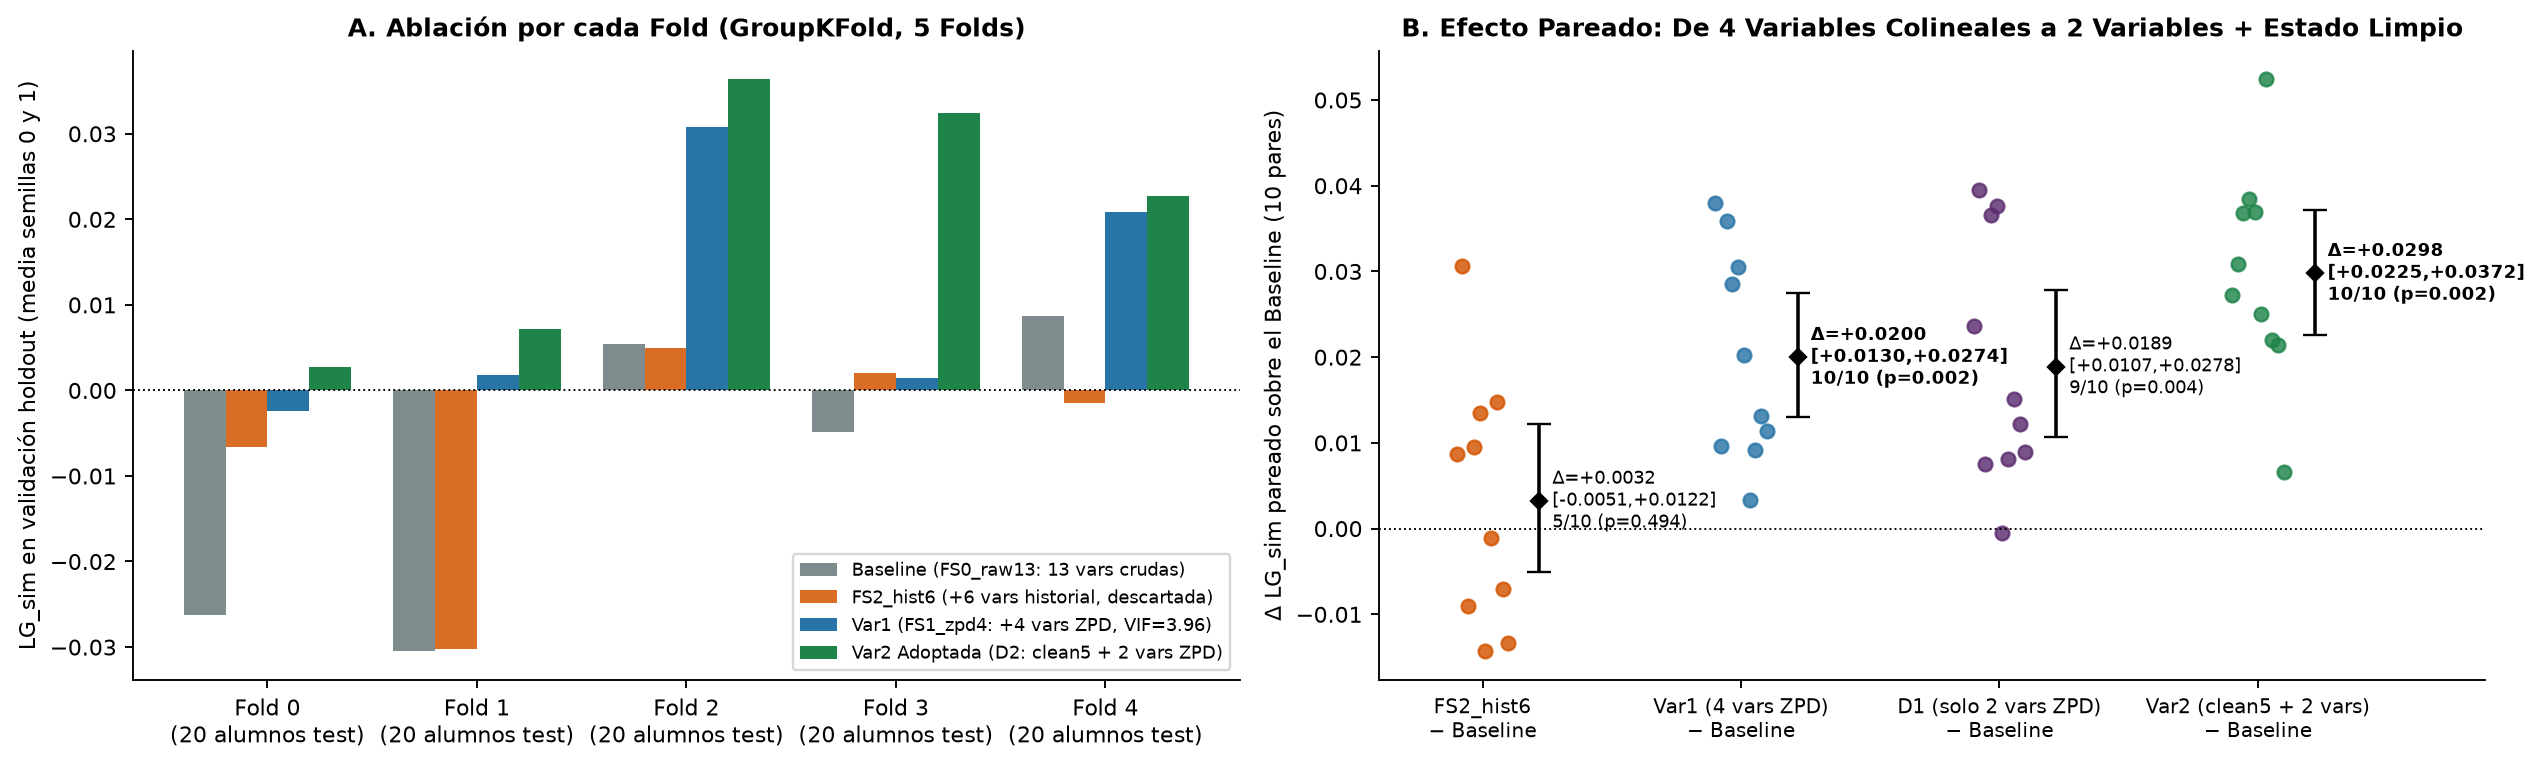

fold,seed,PPOlin_FS0_raw13,PPOlin_FS1_zpd4,PPOlin_D1_zpd2,PPOlin_D2_clean5_zpd2,PPOlin_FS2_hist6
0,0,-0.0302,0.0079,-0.0065,-0.0029,-0.0215
0,1,-0.0224,-0.0127,0.0171,0.0085,0.0082
1,0,-0.0269,0.0091,-0.0193,0.0100,-0.0359
1,1,-0.0341,-0.0056,0.0025,0.0044,-0.0246
2,0,0.0012,0.0318,0.0389,0.0382,0.0147
2,1,0.0096,0.0298,0.0091,0.0345,-0.0047
3,0,-0.0028,0.0006,0.0053,0.0496,-0.0039
3,1,-0.0068,0.0023,0.0083,0.0152,0.0080
4,0,0.0054,0.0185,0.0176,0.0269,-0.0017
4,1,0.0120,0.0233,0.0209,0.0185,-0.0014


In [12]:
fig_ab = plt.imread(ROOT / "figures/fe/06_ablacion_por_fold_y_pareada.png")
plt.figure(figsize=(15.2, 4.6))
plt.imshow(fig_ab); plt.axis("off"); plt.tight_layout(); plt.show()

report.per_pair_table(runs_ora).round(4)

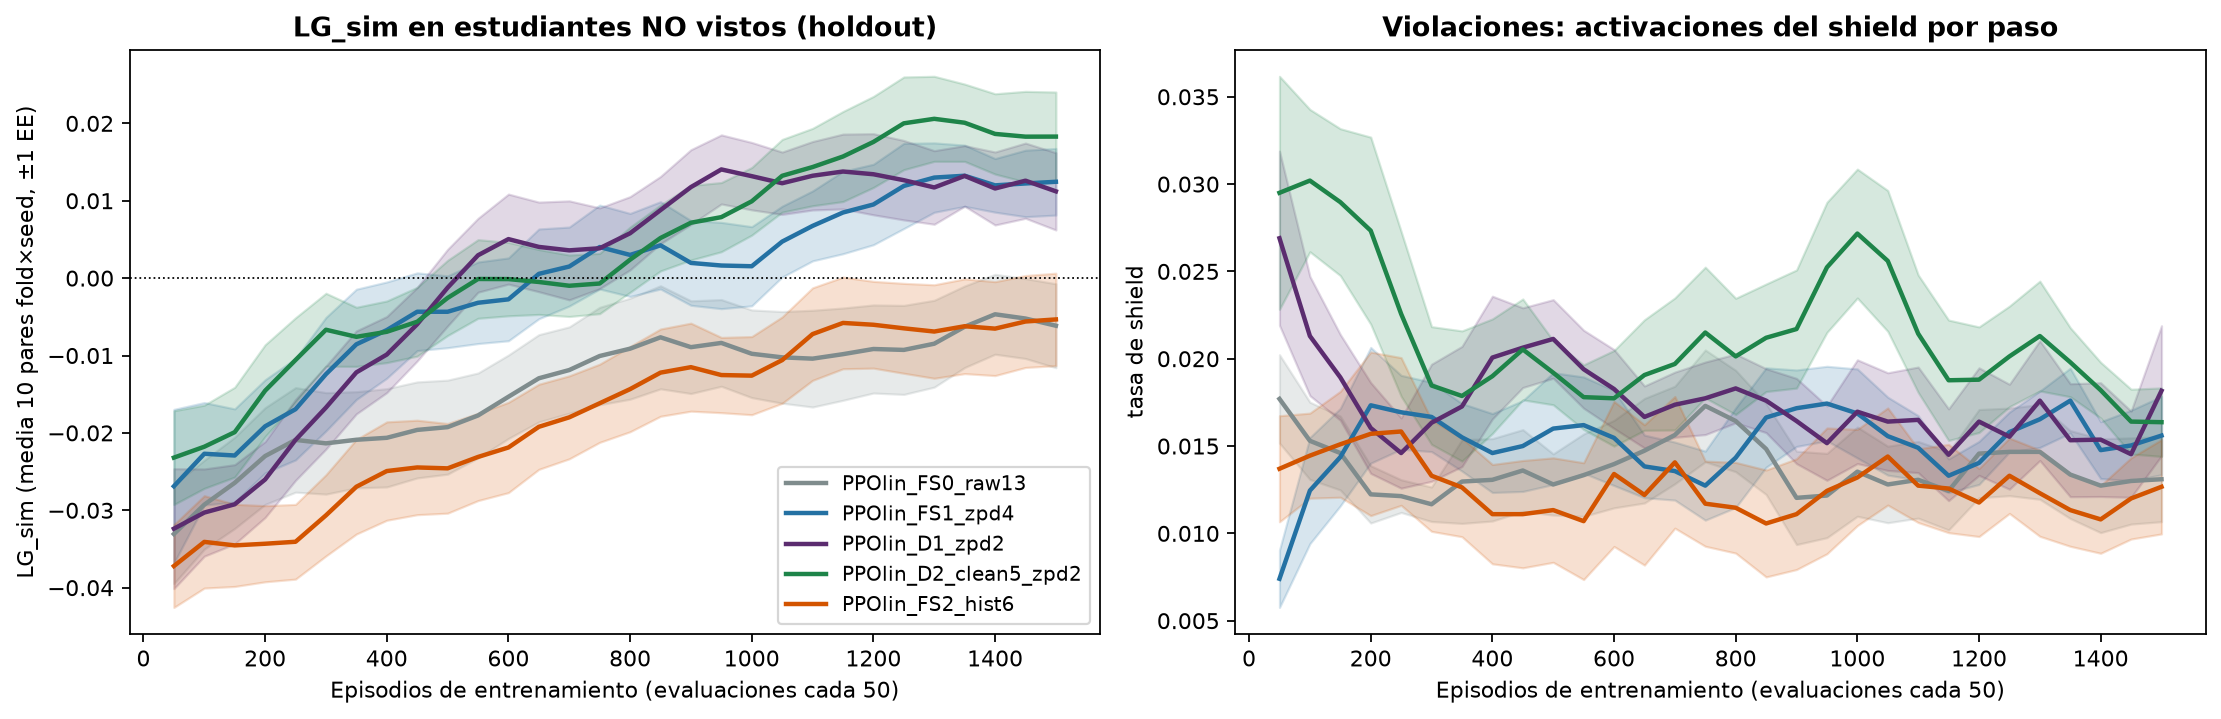

In [13]:
fig_c = plt.imread(ROOT / "figures/fe/01_curvas_holdout_y_violaciones.png")
plt.figure(figsize=(14, 4.6))
plt.imshow(fig_c); plt.axis("off"); plt.tight_layout(); plt.show()

### 4.2 Costo Computacional y Número de Parámetros

In [14]:
lat_df = report.latency_benchmark(n_decisions=2000, fold=0)
lat_df.round(4)

Variante,n_rasgos_estado,n_rasgos_accion,n_parametros_politica,latencia_mediana_ms,latencia_p95_ms,overhead_vs_base_ms
PPOlin_FS0_raw13,13,0,1260,0.0164,0.0207,0.0000
PPOlin_FS1_zpd4,13,4,1264,0.0810,0.1246,0.0645
PPOlin_D1_zpd2,13,2,1262,0.2468,0.6600,0.2304
PPOlin_D2_clean5_zpd2,5,2,542,0.2060,0.5622,0.1896
PPOlin_FS2_hist6,19,0,1800,0.0558,0.1227,0.0394


---
## 5. Prueba de Estrés sin Oráculo ($\hat{\theta}$ Elo Online) y Decisión de Ingeniería

Al sustituir la habilidad verdadera $\theta^*$ por el estimador recursivo Elo ($\hat{\theta}_k \leftarrow \text{clip}(\hat{\theta}_k + 0.1(y_t - \hat{P}_{3PL}), 0, 1)$ inicializado en $0.5$), `PPOlin_D2_clean5_zpd2` mantiene ventaja positiva sobre el `Baseline` ($\Delta LG = +0.0110$, ganando en $4/5$ folds) y supera también a `PPOlin_FS1_zpd4` en régimen observable.

In [15]:
_, runs_elo = report.load_runs(str(ROOT), "elo")
rob_df, rob_stats = report.robustness_table(runs_ora, runs_elo)
rob_df.round(4)

Variante,LG oráculo θ* (seed 0),LG observable θ̂ Elo (seed 0),Δ (θ̂ − θ*)
PPOlin_FS0_raw13,-0.0106,-0.0101,0.0005
PPOlin_FS1_zpd4,0.0136,-0.0006,-0.0141
PPOlin_D2_clean5_zpd2,0.0244,0.0009,-0.0234


---
## 6. Matriz de Decisión Final y Protocolo de Transición a Aula Real

### 6.1 Decisión sobre cada variante de datos

| Variante | $\Delta LG_{\text{sim}}$ vs. Baseline | $p_{\text{Holm}}$ | Pares ganados | Folds $>0$ | $\text{VIF}_{\max}$ | Parámetros | Decisión | Justificación técnica |
|---|:---:|:---:|:---:|:---:|:---:|---:|:---:|---|
| **`PPOlin_D2_clean5_zpd2`** | **$+0.0298$** | **$0.006$** | **$10/10$** | **$5/5$** | **$2.12$** | **$542$** | **ADOPTAR** | Duplica el $LG$ de `Var1` ($+0.0203$ vs. $+0.0105$), reduce $57\%$ los parámetros al eliminar 8 canales muertos/ruido y 2 variables ZPD colineales, y alcanza el LG del baseline en $275$ episodios ($-63\%$). |
| **`PPOlin_FS1_zpd4`** | $+0.0200$ | $0.006$ | $10/10$ | $4/5$ | $3.96$ | $1\,264$ | **SUPERADA POR `D2`** | Demuestra el valor del acoplamiento ZPD, pero sufre colinealidad ($r=0.849$) e inyección de ruido $\sigma_{1..3}$ amplificado $34.6\times$ en el estado. |
| **`PPOlin_D1_zpd2`** | $+0.0189$ | $0.008$ | $9/10$ | $3/5$ | $2.12$ | $1\,262$ | **ABLACIÓN INTERMEDIA** | Confirma que 2 variables ZPD (`abs_gap`, `zpd_hit`) retienen el $95\%$ del efecto de las 4 variables antes de limpiar el estado. |
| **`PPOlin_FS2_hist6`** | $+0.0032$ | $0.494$ | $5/10$ | $2/5$ | $\infty$ | $1\,800$ | **DESCARTAR** | Sin las coordenadas ZPD no resuelve la no-separabilidad lineal ($\text{AUC}=0.500$, $\text{Brier}=0.1690$). |

### 6.2 Transición del Simulador al Piloto con Estudiantes Reales

| Componente | En este estudio in-silico | En el despliegue con estudiantes reales |
|---|---|---|
| **Vector de estado (`clean5`)** | $[\theta_1, \theta_2, \theta_3, t/H, b_{t-1}] \in \mathbb{R}^5$ (sin los 8 canales constantes/ruido). | $[\hat{\theta}_1, \hat{\theta}_2, \hat{\theta}_3, t/H, b_{t-1}] \in \mathbb{R}^5$, donde $\hat{\theta}_k$ se inicializa mediante un pretest diagnóstico de 6 ítems (2 por competencia) y se actualiza tras cada respuesta con IRT bayesiano / Elo. |
| **Las 2 variables ZPD (`zpd2`)** | `zpd_hit` $= \overline{\mathbb{1}[|\theta_k - b_{adj}|<0.5]}$ y `abs_gap` $= \overline{|\theta_k - b_{adj}|}$ por texto-nivel. | **Misma función `action_features(theta_hat)`**: solo reemplaza la tabla `item_bank.csv` sintética por los parámetros $b_i$ calibrados en el piloto ($N \ge 60$ alumnos vía Elo multimodelo; Pelánek, 2016) y aplica calibración de Platt sobre el clasificador de transición. |
| **Seguridad pedagógica (CMDP)** | Escudo determinista ante racha $\ge 4$ errores consecutivos ($\text{nivel} \leftarrow 0$). | Mismo escudo en producción más restricción de acción segura ($|\hat{\theta}_k - b_{adj}| \le 0.6$) para impedir la asignación de textos fuera del rango calibrado del alumno. |